# A/B test analysis: Cookie Cats, gate at level 30 or level 40?

**Question:** Cookie Cats is a mobile puzzle game. At some point the game puts a *gate* in front of the player. The player must wait, or pay, before going on. The first gate was at level 30. In this test, some new players got the first gate at **level 40** instead.
Does moving the gate change how many players come back to the game?

**The data:** one row per player who installed the game during the test.

| Column | Meaning |
|---|---|
| `userid` | Player ID |
| `version` | Test group: `gate_30` (the current game, control) or `gate_40` (the change, variant) |
| `sum_gamerounds` | Rounds played in the first 14 days after install |
| `retention_1` | `True` if the player came back 1 day after install |
| `retention_7` | `True` if the player came back 7 days after install |

**Plan:**
1. Check the data and the test set-up (was the 50/50 split really 50/50?)
2. Compare 1-day and 7-day retention, with confidence intervals and tests
3. Check game rounds as a second view of engagement
4. Check if the test was big enough to see a small change
5. Write the result and its limits

## 1. Set-up and data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

DATA_PATH = Path("data/cookie_cats.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Put cookie_cats.csv in the data/ folder. The README has the download link.")

df = pd.read_csv(DATA_PATH)
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [2]:
# Chart style: two colours only, one for each test group, the same in every chart.
BLUE, ORANGE = "#2a78d6", "#eb6834"   # gate_30 (control), gate_40 (variant)
INK, INK_SOFT, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3de"
COLORS = {"gate_30": BLUE, "gate_40": ORANGE}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False,
})

### Basic checks

In [3]:
print("Rows and columns:", df.shape)
print("Duplicate player IDs:", int(df["userid"].duplicated().sum()))
print()
print("Missing values per column:")
print(df.isna().sum().to_string())

Rows and columns: (90189, 5)
Duplicate player IDs: 0

Missing values per column:
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0


In [4]:
group_counts = df["version"].value_counts().sort_index()
group_counts

version
gate_30    44700
gate_40    45489
Name: count, dtype: int64

### Was the split really 50/50?
If players were assigned at random with a 50/50 split, the two groups should be close to the same size. A group-size gap that is too big for chance is called a *sample ratio mismatch*. It can mean that something went wrong in the test set-up, for example a bug that sends some players to one group only.
I use a chi-square test against an equal split. Many teams treat a p-value below **0.001** as a serious warning.

In [5]:
observed = group_counts.loc[["gate_30", "gate_40"]].to_numpy()
chi2, p_srm = stats.chisquare(observed)   # the default expectation is an equal split

print(f"gate_30: {observed[0]:,} players ({observed[0] / observed.sum():.2%})")
print(f"gate_40: {observed[1]:,} players ({observed[1] / observed.sum():.2%})")
print(f"Chi-square = {chi2:.2f}, p-value = {p_srm:.4f}")
print("Serious warning (p < 0.001)?", "YES" if p_srm < 0.001 else "no")

gate_30: 44,700 players (49.56%)
gate_40: 45,489 players (50.44%)
Chi-square = 6.90, p-value = 0.0086
Serious warning (p < 0.001)? no


**Reading:** `gate_40` has 789 more players than `gate_30` (50.44% against 49.56%). The p-value is 0.0086. This is below 0.05 but above the 0.001 warning line, so it is a **small flag, not a stop sign**. A gap this size would happen about once in 120 fair tests. I continue, but I keep it in the list of limits at the end. In a real team I would also ask how players were assigned.

### Extreme values in game rounds
`sum_gamerounds` is very skewed: most players play a few rounds and a few play a lot. I check the biggest values before using this column.

In [6]:
cols = ["userid", "version", "sum_gamerounds", "retention_1", "retention_7"]
df.nlargest(5, "sum_gamerounds")[cols]

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False
43671,4832608,gate_30,2438,True,True
48188,5346171,gate_40,2294,True,True


In [7]:
print("Players with 0 rounds:", int((df["sum_gamerounds"] == 0).sum()),
      f"({(df['sum_gamerounds'] == 0).mean():.1%})")
df["sum_gamerounds"].quantile([0.5, 0.75, 0.9, 0.99, 0.999]).rename("rounds at percentile")

Players with 0 rounds: 3994 (4.4%)


0.500      16.000
0.750      51.000
0.900     134.000
0.990     493.000
0.999    1073.624
Name: rounds at percentile, dtype: float64

One player has played about 50,000 rounds, far more than anyone else. This may be a data error or an unusual player.
I keep this player in the **retention** analysis, because retention is a yes/no outcome and one player cannot move it. I handle the extreme value with care in the **game rounds** analysis later.

## 2. Retention: did more players come back?
**Control:** `gate_30`. **Variant:** `gate_40`. Both retention metrics are yes/no, so I compare two proportions.
For each metric I report:
- the retention rate in each group, and the difference in **percentage points** (pp)
- a 95% confidence interval for the difference
- a two-sided z-test for two proportions (null hypothesis: no difference)
- a bootstrap interval as a second check
- a Holm correction, because I test two metrics

In [8]:
def two_prop_test(x1, n1, x2, n2, alpha=0.05):
    """Compare two proportions. Group 1 is the control, group 2 is the variant."""
    p1, p2 = x1 / n1, x2 / n2
    diff = p2 - p1
    p_pool = (x1 + x2) / (n1 + n2)
    se_test = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))   # standard error under "no difference"
    z = diff / se_test
    p_value = 2 * stats.norm.sf(abs(z))
    se_ci = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)      # standard error for the interval
    margin = stats.norm.ppf(1 - alpha / 2) * se_ci
    return {"p1": p1, "p2": p2, "diff": diff, "rel_change": diff / p1,
            "ci_low": diff - margin, "ci_high": diff + margin, "z": z, "p_value": p_value}


def holm_adjust(p_values):
    """Holm step-down correction for several tests."""
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty_like(p)
    running_max = 0.0
    for rank, idx in enumerate(order):
        running_max = max(running_max, (len(p) - rank) * p[idx])
        adjusted[idx] = min(1.0, running_max)
    return adjusted


def bootstrap_diff(x1, n1, x2, n2, draws=20_000, seed=42):
    """Bootstrap the difference in proportions.
    For a yes/no outcome, resampling the players is the same as drawing the number of
    'yes' from a Binomial(n, observed rate), so this is fast and exact in distribution."""
    rng = np.random.default_rng(seed)
    d = rng.binomial(n2, x2 / n2, draws) / n2 - rng.binomial(n1, x1 / n1, draws) / n1
    return d, np.percentile(d, [2.5, 97.5])

In [9]:
control = df[df["version"] == "gate_30"]
variant = df[df["version"] == "gate_40"]
n1, n2 = len(control), len(variant)

rows, boot_draws = [], {}
for metric in ["retention_1", "retention_7"]:
    x1, x2 = int(control[metric].sum()), int(variant[metric].sum())
    r = two_prop_test(x1, n1, x2, n2)
    d, (b_low, b_high) = bootstrap_diff(x1, n1, x2, n2)
    boot_draws[metric] = d
    rows.append({
        "metric": metric,
        "gate_30 rate": r["p1"], "gate_40 rate": r["p2"],
        "difference (pp)": r["diff"] * 100,
        "95% CI low (pp)": r["ci_low"] * 100, "95% CI high (pp)": r["ci_high"] * 100,
        "relative change": r["rel_change"],
        "z": r["z"], "p-value": r["p_value"],
        "bootstrap CI low (pp)": b_low * 100, "bootstrap CI high (pp)": b_high * 100,
    })

results = pd.DataFrame(rows).set_index("metric")
results["p-value (Holm)"] = holm_adjust(results["p-value"].to_numpy())

shown = results.copy()
shown["gate_30 rate"] = (shown["gate_30 rate"] * 100).round(2).astype(str) + "%"
shown["gate_40 rate"] = (shown["gate_40 rate"] * 100).round(2).astype(str) + "%"
shown["relative change"] = (shown["relative change"] * 100).round(2).astype(str) + "%"
shown = shown.round({"difference (pp)": 3, "95% CI low (pp)": 3, "95% CI high (pp)": 3, "z": 2,
                     "p-value": 4, "bootstrap CI low (pp)": 3, "bootstrap CI high (pp)": 3,
                     "p-value (Holm)": 4})
shown.T

metric,retention_1,retention_7
gate_30 rate,44.82%,19.02%
gate_40 rate,44.23%,18.2%
difference (pp),-0.591,-0.82
95% CI low (pp),-1.239,-1.328
95% CI high (pp),0.058,-0.312
relative change,-1.32%,-4.31%
z,-1.78,-3.16
p-value,0.0744,0.0016
bootstrap CI low (pp),-1.238,-1.327
bootstrap CI high (pp),0.057,-0.309


**Reading the table:**
- **1-day retention:** 44.82% with `gate_30` and 44.23% with `gate_40`. That is 0.59 percentage points lower. The 95% interval (-1.24 to +0.06 pp) includes zero, and the p-value is 0.074. So this difference is **not statistically significant**.
- **7-day retention:** 19.02% with `gate_30` and 18.20% with `gate_40`. That is 0.82 percentage points lower, or 4.3% fewer players coming back. The 95% interval (-1.33 to -0.31 pp) stays below zero. The p-value is 0.0016, or **0.0031 after the Holm correction**. So this difference **is statistically significant**.
- The bootstrap intervals are almost the same as the normal-approximation intervals, so the result does not depend on the method.

A second way to say the same thing: with a uniform Beta prior on each retention rate, what is the chance that the `gate_40` rate is *lower* than the `gate_30` rate?

In [10]:
rng = np.random.default_rng(7)
for metric in ["retention_1", "retention_7"]:
    x1, x2 = int(control[metric].sum()), int(variant[metric].sum())
    post_control = rng.beta(1 + x1, 1 + n1 - x1, 200_000)
    post_variant = rng.beta(1 + x2, 1 + n2 - x2, 200_000)
    print(f"{metric}: chance that gate_40 is lower than gate_30 = {(post_variant < post_control).mean():.1%}")

retention_1: chance that gate_40 is lower than gate_30 = 96.3%
retention_7: chance that gate_40 is lower than gate_30 = 99.9%


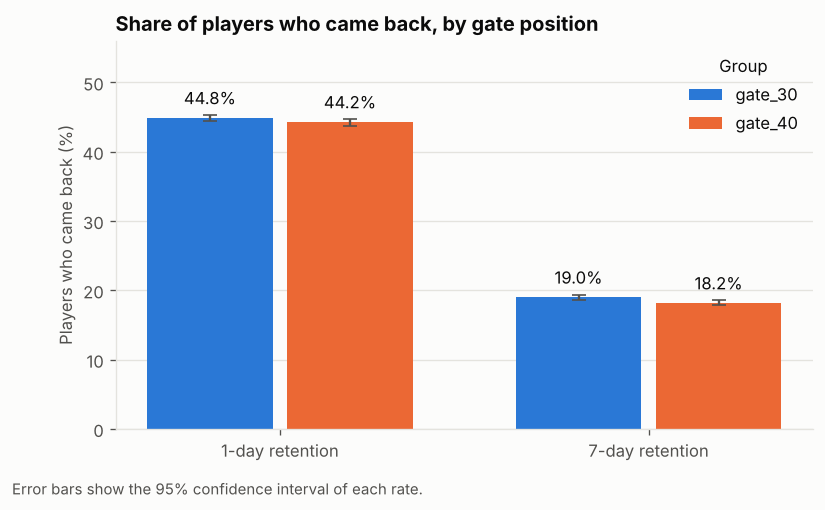

In [11]:
# Chart 1: retention rate by group with 95% confidence intervals.
fig, ax = plt.subplots(figsize=(7.5, 4.2))
metrics = ["retention_1", "retention_7"]
labels = ["1-day retention", "7-day retention"]
width = 0.34
for i, (group, data) in enumerate([("gate_30", control), ("gate_40", variant)]):
    rates = np.array([data[m].mean() for m in metrics])
    errs = 1.96 * np.sqrt(rates * (1 - rates) / len(data))
    xs = np.arange(len(metrics)) + (i - 0.5) * (width + 0.04)
    ax.bar(xs, rates * 100, width, color=COLORS[group], label=group)
    ax.errorbar(xs, rates * 100, yerr=errs * 100, fmt="none", ecolor=INK_SOFT, elinewidth=1.4, capsize=4)
    for x, rate, err in zip(xs, rates, errs):
        ax.text(x, (rate + err) * 100 + 1.0, f"{rate:.1%}", ha="center", va="bottom", fontsize=10, color=INK)
ax.set_xticks(np.arange(len(metrics)))
ax.set_xticklabels(labels)
ax.set_ylabel("Players who came back (%)")
ax.set_ylim(0, 56)
ax.grid(axis="x", visible=False)
ax.set_title("Share of players who came back, by gate position")
ax.legend(title="Group", loc="upper right")
fig.text(0.01, -0.02, "Error bars show the 95% confidence interval of each rate.", fontsize=9, color=INK_SOFT)
plt.show()

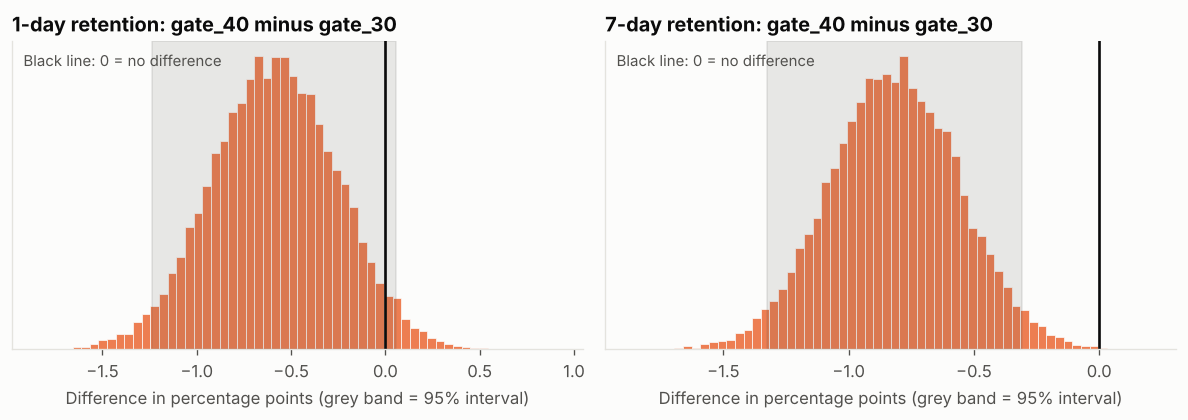

In [12]:
# Chart 2: how big is the difference, and how sure are we? (bootstrap draws, in percentage points)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, metric, label in zip(axes, metrics, labels):
    d = boot_draws[metric] * 100
    low, high = np.percentile(d, [2.5, 97.5])
    ax.hist(d, bins=60, color=ORANGE, alpha=0.85, edgecolor=SURFACE, linewidth=0.5)
    ax.axvline(0, color=INK, linewidth=1.6)
    ax.axvspan(low, high, color=INK_SOFT, alpha=0.12)
    ax.set_title(f"{label}: gate_40 minus gate_30")
    ax.set_xlabel("Difference in percentage points (grey band = 95% interval)")
    ax.set_yticks([])
    ax.grid(False)
    ax.text(0.02, 0.92, "Black line: 0 = no difference", transform=ax.transAxes, fontsize=9, color=INK_SOFT)
fig.tight_layout()
plt.show()

## 3. Game rounds: a second view of engagement
Retention is the main result. Game rounds is a second check: did players play more or fewer rounds?
Rounds are very skewed, so the t-test is a poor choice. I use the **Mann-Whitney U test**, which compares the whole distributions, and I compare medians. I also show the mean with and without the single biggest value.

In [13]:
rounds = df.groupby("version")["sum_gamerounds"].agg(["count", "mean", "median"]).round(2)
no_outlier = df.drop(index=df["sum_gamerounds"].idxmax())
rounds["mean without the biggest value"] = no_outlier.groupby("version")["sum_gamerounds"].mean().round(2)
rounds

,count,mean,median,mean without the biggest value
version,,,,
gate_30,44700,52.46,17.0,51.34
gate_40,45489,51.30,16.0,51.30


In [14]:
a = control["sum_gamerounds"].to_numpy()
b = variant["sum_gamerounds"].to_numpy()

mw = stats.mannwhitneyu(b, a, alternative="two-sided")
prob_more = mw.statistic / (len(a) * len(b))   # chance a random gate_40 player played more than a random gate_30 player

rng = np.random.default_rng(11)
median_diffs = np.array([
    np.median(rng.choice(b, len(b))) - np.median(rng.choice(a, len(a))) for _ in range(2000)
])
m_low, m_high = np.percentile(median_diffs, [2.5, 97.5])

print(f"Median rounds: gate_30 = {np.median(a):.0f}, gate_40 = {np.median(b):.0f}")
print(f"Difference in medians = {np.median(b) - np.median(a):.0f} rounds (bootstrap 95% interval: {m_low:.0f} to {m_high:.0f})")
print(f"Mann-Whitney U p-value = {mw.pvalue:.4f}")
print(f"Chance a random gate_40 player played more rounds than a random gate_30 player = {prob_more:.1%} (50% means no difference)")

Median rounds: gate_30 = 17, gate_40 = 16
Difference in medians = -1 rounds (bootstrap 95% interval: -1 to 0)
Mann-Whitney U p-value = 0.0502
Chance a random gate_40 player played more rounds than a random gate_30 player = 49.6% (50% means no difference)


**Reading:** the average looks different at first (52.46 against 51.30 rounds), but this is caused by **one player** in `gate_30` with 49,854 rounds. Without that player the means are 51.34 and 51.30, almost the same. The medians are 17 and 16 rounds. The Mann-Whitney p-value is 0.0502, right on the edge of 0.05, and the chance that a random `gate_40` player played more than a random `gate_30` player is 49.6% (50% would mean no difference). In short: there is **at most a very small difference in rounds played**, much smaller than the retention difference.

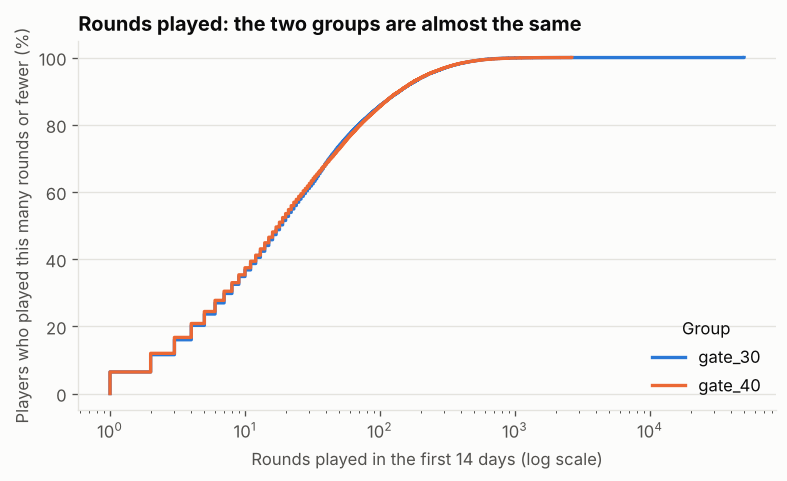

In [15]:
# Chart 3: share of players who played at most this many rounds (log scale on the x axis).
# Players with 0 rounds are not drawn, because a log scale cannot show zero.
fig, ax = plt.subplots(figsize=(7.5, 4.0))
for group, data in [("gate_30", control), ("gate_40", variant)]:
    vals = np.sort(data.loc[data["sum_gamerounds"] > 0, "sum_gamerounds"].to_numpy())
    share = np.arange(1, len(vals) + 1) / len(vals)
    ax.step(vals, share * 100, where="post", linewidth=2, color=COLORS[group], label=group)
ax.set_xscale("log")
ax.set_xlabel("Rounds played in the first 14 days (log scale)")
ax.set_ylabel("Players who played this many rounds or fewer (%)")
ax.set_title("Rounds played: the two groups are almost the same")
ax.legend(title="Group", loc="lower right")
ax.grid(axis="x", visible=False)
plt.show()

## 4. Was the test big enough?
A result with "no significant difference" is only useful if the test could have seen a *useful* difference. Two numbers help:
- the **smallest change the test could reliably detect** with the group sizes we have (80% power, 5% significance)
- the **number of players per group needed** to detect a smaller change

These use the standard normal approximation for two proportions, so treat them as good estimates, not exact values.

In [16]:
def sample_size_per_group(p_base, change, alpha=0.05, power=0.80):
    """Players needed in each group to detect a change in a proportion."""
    p1, p2 = p_base, p_base + change
    p_bar = (p1 + p2) / 2
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    num = (z_a * np.sqrt(2 * p_bar * (1 - p_bar)) + z_b * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2
    return int(np.ceil(num / change ** 2))


def smallest_detectable_change(p_base, n_per_group, alpha=0.05, power=0.80):
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return (z_a + z_b) * np.sqrt(2 * p_base * (1 - p_base) / n_per_group)


rows = []
n_per_group = min(n1, n2)
for metric in ["retention_1", "retention_7"]:
    base = control[metric].mean()
    row = {"metric": metric, "gate_30 rate": f"{base:.2%}",
           "smallest change this test could detect (pp)": round(smallest_detectable_change(base, n_per_group) * 100, 2)}
    for change_pp in [0.25, 0.5, 1.0]:
        row[f"players per group for {change_pp} pp"] = f"{sample_size_per_group(base, change_pp / 100):,}"
    rows.append(row)

pd.DataFrame(rows).set_index("metric").T

metric,retention_1,retention_7
gate_30 rate,44.82%,19.02%
smallest change this test could detect (pp),0.93,0.74
players per group for 0.25 pp,"621,489","388,796"
players per group for 0.5 pp,"155,450","97,682"
players per group for 1.0 pp,"38,900","24,660"


**Reading:** each group has about 45,000 players. With this size the test can reliably see a change of about **0.9 pp in 1-day retention** and **0.7 pp in 7-day retention**. The 7-day change we found (0.82 pp) is bigger than that, so it was detectable, and we did detect it. The 1-day change we found (0.59 pp) is *smaller* than the test can reliably see, so "not significant" for 1-day retention does **not** mean "no effect". To measure a 0.5 pp change in 1-day retention we would need about 155,000 players per group.

## 5. Result and recommendation

**Recommendation: keep the first gate at level 30.**

| | gate_30 | gate_40 | Difference | Significant? |
|---|---|---|---|---|
| 1-day retention | 44.82% | 44.23% | -0.59 pp (95% CI -1.24 to +0.06) | No (p = 0.074) |
| 7-day retention | 19.02% | 18.20% | -0.82 pp (95% CI -1.33 to -0.31) | Yes (p = 0.0031 after Holm) |
| Rounds played (median) | 17 | 16 | -1 round | Borderline (p = 0.0502) |

- Moving the gate to level 40 **did not improve** any measure. It **lowered 7-day retention** by about 0.8 percentage points (4.3% fewer returning players). All three measures point the same way, and the 7-day result holds after correcting for two tests.
- A change of this size looks small, but retention compounds: fewer players returning after 7 days means fewer players in the game later.

**Limits of this analysis:**
- **No revenue data.** A gate exists to make money (waiting players may pay or watch ads). A later gate could change revenue, and this data cannot show it. A full decision needs revenue per player.
- **Mild sample ratio flag.** The groups differ in size a little more than chance usually allows (p = 0.0086). It is not a serious warning, but I cannot check how players were assigned.
- **Short window.** Retention is measured at 1 and 7 days. Longer-term effects are unknown.
- **Diluted effect.** Players who quit before they reach a gate cannot be affected by it, so the true effect on players who *do* reach the gate is probably larger than the average shown here. I did not filter on rounds played, because rounds can themselves be changed by the test and that would bias the comparison.
- **One test, one game.** The result tells us about this game and this change only.

**What I would do next:** get revenue per player for both groups, then decide with retention and revenue together. If revenue is higher with `gate_40`, the choice becomes a trade-off between short-term revenue and long-term retention.